# Diagnostic-Driven Hybrid ML for ECG Classification

## Dataset
MIT-BIH Arrhythmia Database

## Research Framework
1. Data Diagnostics
2. Condition Mapping
3. Hybrid Strategy Selection
4. Model Training
5. Performance Evaluation

## Objective
To investigate whether a diagnostic-driven framework
for selecting hybrid machine learning strategies can
be applied to healthcare ECG data.

In [6]:
import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt

import statsmodels
import wfdb
import neurokit2 as nk

from statsmodels.tsa.stattools import adfuller, kpss

print("Environment successfully initialized")
print("------------------------------")
print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Statsmodels:", statsmodels.__version__)
print("WFDB:", wfdb.__version__)
print("NeuroKit2:", nk.__version__)

Environment successfully initialized
------------------------------
Python: 3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:15:26) [Clang 20.1.8 ]
NumPy: 2.5.4
Pandas: 3.1.1
SciPy: 1.18.1
Statsmodels: 0.15.0
WFDB: 4.3.1
NeuroKit2: 0.3.0


In [8]:
from pathlib import Path

PROJECT_DIR = Path.cwd() / "ECG_Research"
DATA_DIR = PROJECT_DIR / "data" / "mitbih"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

for folder in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)
print("Folders created successfully!")

Project directory: /Users/hmdsahed/ECG Prof. Ozaydin/ECG_Research
Dataset directory: /Users/hmdsahed/ECG Prof. Ozaydin/ECG_Research/data/mitbih
Folders created successfully!


In [10]:
import wfdb

record = wfdb.rdrecord(
    "100",
    pn_dir="mitdb",
    physical=True
)

annotations = wfdb.rdann(
    "100",
    "atr",
    pn_dir="mitdb"
)

print("Recording downloaded successfully!")
print("Signal shape:", record.p_signal.shape)
print("Sampling frequency:", record.fs)
print("Channels:", record.sig_name)
print("Annotations:", len(annotations.sample))

Recording downloaded successfully!
Signal shape: (650000, 2)
Sampling frequency: 360
Channels: ['MLII', 'V5']
Annotations: 2274


## 3. Initial ECG Data Loading

### 3.1 Loading the MIT-BIH Recording

The MIT-BIH Arrhythmia Database was accessed using the WFDB Python library. Recording 100 was selected for the initial data inspection.

The ECG signal and its corresponding expert annotations were successfully loaded.

### 3.2 Recording Information

The initial recording contains the following characteristics:

| Property | Value |
|---|---:|
| Recording ID | 100 |
| Total samples | 650,000 |
| Sampling frequency | 360 Hz |
| Number of channels | 2 |
| Channel 1 | MLII |
| Channel 2 | V5 |
| Number of annotations | 2,274 |
| Recording duration | Approximately 30.1 minutes |

### 3.3 Data Description

The recording contains two ECG channels:

- **MLII:** Modified Lead II ECG signal.
- **V5:** Precordial ECG signal.

The database also provides expert annotations that identify cardiac events at specific sample positions.

These annotations will be used to investigate heartbeat categories and define the classification targets.

### 3.4 Next Step

The next stage will involve:

1. Visual inspection of both ECG channels.
2. Examination of the expert annotation symbols.
3. Analysis of the annotation frequency and class distribution.
4. Selection of an appropriate ECG classification task.

These initial investigations will establish the data characteristics before applying the diagnostic-driven framework.

## 4. ECG Signal Visualization

### 4.1 Visual Inspection of ECG Signals

The first 10 seconds of the ECG recording will be visualized for both MLII and V5 channels.

The purpose of this step is to:

- Observe the general waveform morphology.
- Examine the amplitude and temporal patterns.
- Identify visible signal variations and potential noise.
- Compare the waveform characteristics between the two channels.

This visual inspection provides an initial understanding of the ECG signals before performing statistical and signal-level diagnostics.

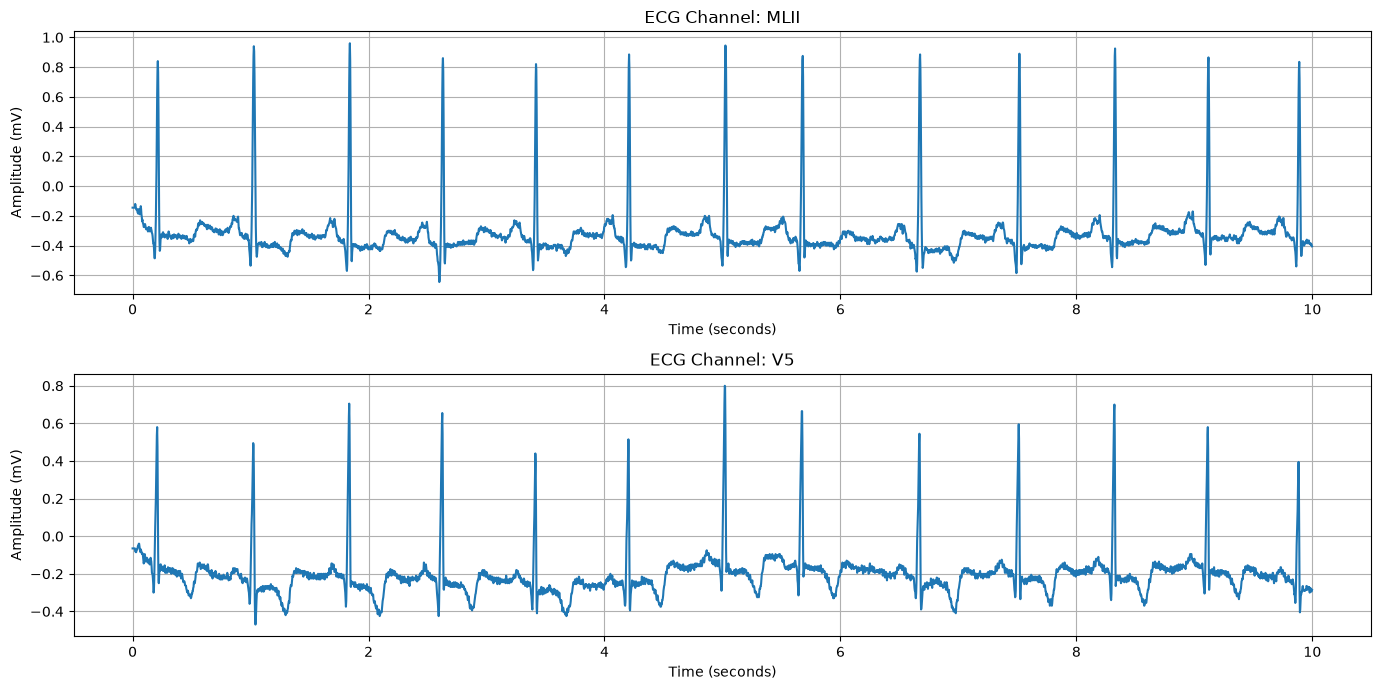

In [14]:
import numpy as np
import matplotlib.pyplot as plt

duration = 10
samples = int(duration * record.fs)

time = np.arange(samples) / record.fs

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

for i, channel in enumerate(record.sig_name):
    axes[i].plot(time, record.p_signal[:samples, i])
    axes[i].set_title(f"ECG Channel: {channel}")
    axes[i].set_xlabel("Time (seconds)")
    axes[i].set_ylabel("Amplitude (mV)")
    axes[i].grid(True)

plt.tight_layout()
plt.show()

### 4.3 Initial Observations

The visualization of the first 10 seconds of recording 100 shows identifiable and repeating ECG waveform patterns in both MLII and V5 channels.

The following observations were made:

- Both channels contain prominent peaks associated with cardiac activity.
- The waveform morphology differs between MLII and V5.
- Variations in signal amplitude and baseline are visible across the recording.
- The signals show temporal variations that require further statistical investigation.

These observations provide an initial understanding of the ECG signals. However, visual inspection alone is insufficient to determine stationarity, signal quality, or the presence of clinically abnormal heartbeats.

Further statistical and signal-level diagnostics will be conducted to investigate these characteristics.

In [17]:
import pandas as pd

annotation_df = pd.DataFrame({
    "sample": annotations.sample,
    "time_seconds": annotations.sample / record.fs,
    "symbol": annotations.symbol
})

print("First 15 annotations:")
display(annotation_df.head(15))

print("\nAnnotation symbol distribution:")
display(annotation_df["symbol"].value_counts().to_frame("count"))

First 15 annotations:


,sample,time_seconds,symbol
0,18,0.050000,+
1,77,0.213889,N
2,370,1.027778,N
3,662,1.838889,N
4,946,2.627778,N
5,1231,3.419444,N
6,1515,4.208333,N
7,1809,5.025000,N
8,2044,5.677778,A
9,2402,6.672222,N



Annotation symbol distribution:


,count
symbol,
N,2239
A,33
+,1
V,1


## 5. ECG Annotation Analysis

### 5.1 Expert Annotation Distribution

The expert annotations associated with MIT-BIH recording 100 were extracted and analysed to examine the distribution of annotated cardiac events.

The annotation distribution is as follows:

| Annotation | Count | Description |
|---|---:|---|
| N | 2,239 | Normal beat |
| A | 33 | Atrial premature beat |
| V | 1 | Premature ventricular contraction |
| + | 1 | Rhythm-change marker |

The `+` annotation represents a rhythm marker rather than a heartbeat category.

### 5.2 Initial Class Imbalance Observation

Considering the three heartbeat categories (N, A, and V), the recording contains:

- Normal beats: 2,239
- Abnormal beats (A and V): 34

This indicates a substantial imbalance between normal and abnormal heartbeat annotations.

The observed imbalance makes recording 100 a useful starting point for investigating class distribution and its implications for machine learning.

### 5.3 Implications for the Proposed Framework

Class imbalance will be considered an important data condition in the diagnostic stage.

Potential strategies, including class weighting and training-only resampling, will be investigated during model development.

However, the final classification scheme and imbalance-handling strategy will be determined after examining the annotation definitions and the complete dataset.

### 5.4 Next Step

The next stage will examine the annotation distribution quantitatively and determine an appropriate heartbeat classification scheme before constructing the machine learning dataset.

In [20]:
# Count heartbeat annotations only (exclude rhythm markers)
beat_df = annotation_df[
    annotation_df["symbol"].isin(["N", "A", "V"])
].copy()

class_counts = beat_df["symbol"].value_counts()

total_beats = class_counts.sum()
normal_count = class_counts["N"]
abnormal_count = class_counts.get("A", 0) + class_counts.get("V", 0)

imbalance_ratio = normal_count / abnormal_count

print("Total heartbeat annotations:", total_beats)
print("Normal beats:", normal_count)
print("Abnormal beats:", abnormal_count)
print("Imbalance ratio (Normal:Abnormal):", round(imbalance_ratio, 2))
print("Abnormal percentage:", round(abnormal_count / total_beats * 100, 2), "%")

Total heartbeat annotations: 2273
Normal beats: 2239
Abnormal beats: 34
Imbalance ratio (Normal:Abnormal): 65.85
Abnormal percentage: 1.5 %


### 5.5 Quantitative Assessment of Class Imbalance

The class distribution was further examined by grouping the heartbeat annotations into normal and abnormal categories.

The results for recording 100 are:

| Measurement | Result |
|---|---:|
| Total heartbeat annotations | 2,273 |
| Normal beats | 2,239 |
| Abnormal beats | 34 |
| Normal-to-abnormal ratio | 65.85:1 |
| Abnormal heartbeat percentage | 1.50% |

The results indicate a substantial class imbalance, with normal beats accounting for approximately 98.5% of the heartbeat annotations.

This finding identifies class imbalance as a potential challenge for ECG classification.

However, these results represent only one recording. Further analysis across the complete MIT-BIH database is required to determine the overall class distribution and assess whether the same imbalance pattern is present across different patients.

## 6. Complete MIT-BIH Dataset Analysis

### 6.1 Objective

The initial analysis examined only recording 100. To obtain a more representative understanding of the dataset, the next stage will investigate all available recordings in the MIT-BIH Arrhythmia Database.

### 6.2 Analysis Plan

The following information will be extracted from each recording:

- Recording identifier.
- Total number of expert annotations.
- Frequency of each annotation symbol.
- Distribution of heartbeat categories.
- Differences in annotation distributions across recordings.

### 6.3 Purpose

This analysis will help determine whether class imbalance is consistent across recordings or varies between patients.

The complete annotation distribution will also support the selection of an appropriate heartbeat classification task.

At this stage, all annotation symbols will be preserved. Non-beat annotations will be distinguished from heartbeat annotations before calculating the final class distribution.

In [28]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.


In [30]:
from collections import Counter
from tqdm.auto import tqdm
import wfdb
import pandas as pd

# Get all MIT-BIH recording IDs
record_list = wfdb.get_record_list("mitdb")

print("Total recordings:", len(record_list))
print("Recording IDs:", record_list)

# Collect annotation information
all_annotations = []
recording_summary = []

for rec_id in tqdm(record_list, desc="Reading annotations"):

    ann = wfdb.rdann(
        rec_id,
        "atr",
        pn_dir="mitdb"
    )

    symbol_counts = Counter(ann.symbol)

    recording_summary.append({
        "record_id": rec_id,
        "total_annotations": len(ann.symbol),
        "unique_symbols": len(symbol_counts)
    })

    for symbol, count in symbol_counts.items():
        all_annotations.append({
            "record_id": rec_id,
            "symbol": symbol,
            "count": count
        })

# Convert results into DataFrames
recording_summary_df = pd.DataFrame(recording_summary)
all_annotations_df = pd.DataFrame(all_annotations)

# Overall annotation distribution
overall_distribution = (
    all_annotations_df
    .groupby("symbol")["count"]
    .sum()
    .sort_values(ascending=False)
    .to_frame("total_count")
)

print("\nRecording summary:")
display(recording_summary_df.head())

print("\nOverall annotation symbol distribution:")
display(overall_distribution)

print("\nTotal recordings processed:",
      len(recording_summary_df))

Total recordings: 48
Recording IDs: ['100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '217', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']


Reading annotations:   0%|          | 0/48 [00:00<?, ?it/s]


Recording summary:


,record_id,total_annotations,unique_symbols
0,100,2274,4
1,101,1874,6
2,102,2192,5
3,103,2091,4
4,104,2311,7



Overall annotation symbol distribution:


,total_count
symbol,
N,75052
L,8075
R,7259
V,7130
/,7028
A,2546
+,1291
f,982
F,803



Total recordings processed: 48


## 6. Complete MIT-BIH Annotation Analysis

### 6.1 Dataset Coverage

The annotation analysis was extended to all 48 recordings in the MIT-BIH Arrhythmia Database.

All 48 recordings were successfully processed using the WFDB library.

For each recording, the analysis extracted:
- Recording identifier.
- Total number of annotations.
- Number of unique annotation symbols.
- Frequency of each annotation symbol.

### 6.2 Overall Annotation Distribution

The aggregated annotation distribution revealed several frequently occurring symbols.

| Symbol | Count |
|---|---:|
| N | 75,052 |
| L | 8,075 |
| R | 7,259 |
| V | 7,130 |
| / | 7,028 |
| A | 2,546 |
| + | 1,291 |
| f | 982 |
| F | 803 |
| ~ | 616 |
| ! | 472 |

Additional less frequent annotation symbols were also identified.

### 6.3 Initial Findings

The complete dataset contains a considerably more diverse annotation distribution than the initial examination of recording 100.

In particular, the presence of multiple heartbeat categories indicates that the classification problem may involve more than simply distinguishing normal and abnormal beats.

However, not all annotation symbols represent heartbeat classes. Therefore, annotation symbols must be grouped and interpreted according to their definitions before calculating the final class distribution.

### 6.4 Next Step

The next stage will identify the heartbeat-related annotation symbols and distinguish them from rhythm markers and other annotation types.

This will establish a reliable basis for calculating class imbalance and defining the classification task.

In [33]:
# Display all annotation symbols and their counts

symbol_summary = (
    all_annotations_df
    .groupby("symbol")["count"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

symbol_summary["percentage"] = (
    symbol_summary["count"] /
    symbol_summary["count"].sum() * 100
)

display(symbol_summary)

,symbol,count,percentage
0,N,75052,66.625831
1,L,8075,7.168411
2,R,7259,6.444024
3,V,7130,6.329507
4,/,7028,6.238959
5,A,2546,2.260158
6,+,1291,1.146058
7,f,982,0.871750
8,F,803,0.712846
9,~,616,0.546841


### 6.5 Heartbeat Annotation Classification

To establish a standardised classification scheme, the AAMI five-class heartbeat grouping will be investigated.

The original MIT-BIH annotation symbols will be mapped into five categories:

- N: Normal and related beats.
- S: Supraventricular ectopic beats.
- V: Ventricular ectopic beats.
- F: Fusion beats.
- Q: Paced and unclassifiable beats.

Non-beat annotations will be excluded from heartbeat classification.

The original annotation symbols will be preserved alongside their mapped categories to maintain traceability.

This classification scheme will provide a consistent basis for analysing class distribution and developing the subsequent machine learning models.

In [36]:
# AAMI five-class annotation mapping

aami_mapping = {
    "N": ["N", "L", "R", "e", "j"],
    "S": ["A", "a", "J", "S"],
    "V": ["V", "E"],
    "F": ["F"],
    "Q": ["/", "f", "Q"]
}

# Reverse mapping: original symbol -> AAMI class
symbol_to_aami = {
    symbol: aami_class
    for aami_class, symbols in aami_mapping.items()
    for symbol in symbols
}

# Calculate total counts for each AAMI class
aami_counts = {}

for aami_class, symbols in aami_mapping.items():
    aami_counts[aami_class] = (
        all_annotations_df[
            all_annotations_df["symbol"].isin(symbols)
        ]["count"].sum()
    )

aami_summary = pd.DataFrame({
    "AAMI_Class": list(aami_counts.keys()),
    "Total_Beats": list(aami_counts.values())
})

aami_summary["Percentage"] = (
    aami_summary["Total_Beats"] /
    aami_summary["Total_Beats"].sum() * 100
)

print("AAMI Five-Class Distribution:")
display(aami_summary)

print("Total classified beats:", aami_summary["Total_Beats"].sum())

print("\nUnmapped annotation symbols:")
unmapped = symbol_summary[
    ~symbol_summary["symbol"].isin(symbol_to_aami.keys())
]
display(unmapped)

AAMI Five-Class Distribution:


,AAMI_Class,Total_Beats,Percentage
0,N,90631,82.772572
1,S,2781,2.539865
2,V,7236,6.608581
3,F,803,0.733374
4,Q,8043,7.345608


Total classified beats: 109494

Unmapped annotation symbols:


,symbol,count,percentage
6,+,1291,1.146058
9,~,616,0.546841
10,!,472,0.419008
11,"""",437,0.387938
13,x,193,0.171332
15,|,132,0.117180
20,[,6,0.005326
21,],6,0.005326


### 6.6 AAMI Five-Class Heartbeat Distribution

The heartbeat annotations from all 48 MIT-BIH recordings were grouped into five AAMI categories.

The resulting distribution is presented below.

| AAMI Class | Total Beats | Percentage |
|---|---:|---:|
| N | 90,631 | 82.77% |
| S | 2,781 | 2.54% |
| V | 7,236 | 6.61% |
| F | 803 | 0.73% |
| Q | 8,043 | 7.35% |
| **Total** | **109,494** | **100.00%** |

A total of 3,153 annotations were excluded because they did not belong to the selected heartbeat classification categories.

### 6.7 Initial Class Distribution Findings

The results demonstrate substantial class imbalance across the five heartbeat categories.

The N class represents approximately 82.77% of classified heartbeat annotations, whereas the F class represents only 0.73%.

The S and F categories are particularly underrepresented compared with the dominant N category.

These findings identify class imbalance as an important condition for the subsequent diagnostic-driven framework.

However, the current analysis aggregates annotations across all recordings. It does not yet account for patient-independent data splitting or differences in class distribution between individual patients.

### 6.8 Next Step

The next stage will examine class imbalance quantitatively and investigate how the distribution varies across individual recordings.

The classification mapping and recording-level distributions will also be checked before constructing the final machine learning dataset.

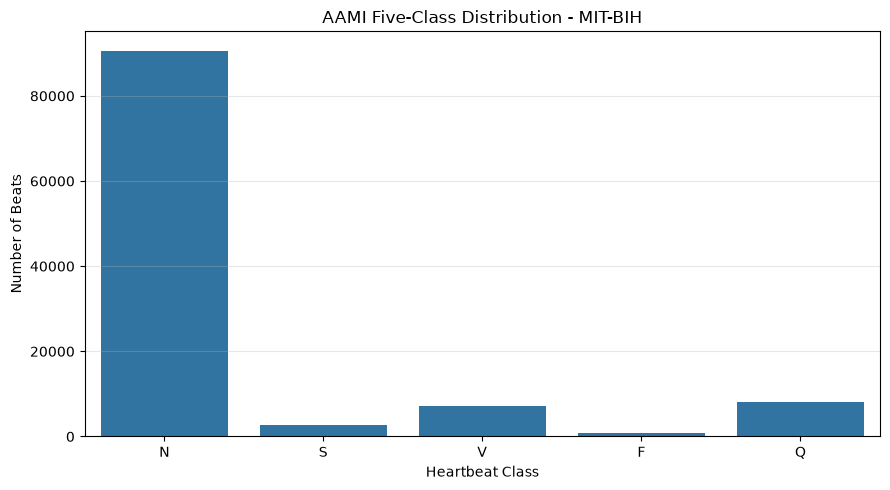

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=aami_summary,
    x="AAMI_Class",
    y="Total_Beats"
)

plt.title("AAMI Five-Class Distribution - MIT-BIH")
plt.xlabel("Heartbeat Class")
plt.ylabel("Number of Beats")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 6.9 Visualization of AAMI Class Distribution

The distribution of the five AAMI heartbeat categories was visualized using a bar chart.

The visualization highlights a substantial difference in the number of observations across classes.

The N category is the dominant class, containing 90,631 beats, while the F category is the least represented, containing 803 beats.

This distribution indicates that the classification task has a significant class imbalance problem.

The visualization provides preliminary evidence that class imbalance should be considered during the diagnostic stage and subsequent model development.

Further analysis will examine the imbalance quantitatively and investigate its variation across individual recordings.

In [42]:
# Calculate majority-to-minority class ratios

majority_count = aami_summary.loc[
    aami_summary["AAMI_Class"] == "N",
    "Total_Beats"
].iloc[0]

imbalance_results = []

for _, row in aami_summary.iterrows():

    class_name = row["AAMI_Class"]
    class_count = row["Total_Beats"]

    imbalance_results.append({
        "Class": class_name,
        "Count": class_count,
        "Percentage": row["Percentage"],
        "N_to_Class_Ratio": round(
            majority_count / class_count, 2
        )
    })

imbalance_df = pd.DataFrame(imbalance_results)

display(imbalance_df)

,Class,Count,Percentage,N_to_Class_Ratio
0,N,90631,82.772572,1.00
1,S,2781,2.539865,32.59
2,V,7236,6.608581,12.53
3,F,803,0.733374,112.87
4,Q,8043,7.345608,11.27


### 6.10 Quantitative Class Imbalance Assessment

The majority-to-minority class ratios were calculated using the N category as the reference class.

| Class | Count | Percentage | N-to-Class Ratio |
|---|---:|---:|---:|
| N | 90,631 | 82.77% | 1.00 |
| S | 2,781 | 2.54% | 32.59 |
| V | 7,236 | 6.61% | 12.53 |
| F | 803 | 0.73% | 112.87 |
| Q | 8,043 | 7.35% | 11.27 |

The results reveal substantial differences in class representation.

The F category has the highest imbalance ratio (112.87:1), followed by S (32.59:1), V (12.53:1), and Q (11.27:1).

These findings indicate that class imbalance varies considerably across heartbeat categories.

Therefore, the diagnostic-driven framework should consider not only the presence of class imbalance but also its severity and distribution across individual classes.

The current ratios are calculated from aggregated annotations and do not yet account for patient-level differences.

In [45]:
# Create recording-level AAMI class distribution

recording_aami = all_annotations_df.copy()

recording_aami["AAMI_Class"] = (
    recording_aami["symbol"].map(symbol_to_aami)
)

recording_aami = recording_aami.dropna(
    subset=["AAMI_Class"]
)

recording_class_counts = (
    recording_aami
    .pivot_table(
        index="record_id",
        columns="AAMI_Class",
        values="count",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)

# Ensure all five classes exist
for cls in ["N", "S", "V", "F", "Q"]:
    if cls not in recording_class_counts.columns:
        recording_class_counts[cls] = 0

print("Recording-level AAMI distribution:")
display(recording_class_counts.head(15))

print("\nNumber of recordings containing each class:")

for cls in ["N", "S", "V", "F", "Q"]:
    present = (recording_class_counts[cls] > 0).sum()
    print(f"{cls}: {present}/48 recordings")

Recording-level AAMI distribution:


AAMI_Class,record_id,F,N,Q,S,V
0,100,0,2239,0,33,1
1,101,0,1860,2,3,0
2,102,0,99,2084,0,4
3,103,0,2082,0,2,0
4,104,0,163,2064,0,2
5,105,0,2526,5,0,41
6,106,0,1507,0,0,520
7,107,0,0,2078,0,59
8,108,2,1740,0,4,17
9,109,2,2492,0,0,38



Number of recordings containing each class:
N: 47/48 recordings
S: 32/48 recordings
V: 37/48 recordings
F: 17/48 recordings
Q: 9/48 recordings


### 6.11 Recording-Level Class Distribution

The AAMI heartbeat categories were examined separately across all 48 MIT-BIH recordings to investigate how class representation varies between recordings.

The number of recordings containing each category is shown below.

| Class | Recordings Containing Class | Coverage |
|---|---:|---:|
| N | 47/48 | 97.9% |
| S | 32/48 | 66.7% |
| V | 37/48 | 77.1% |
| F | 17/48 | 35.4% |
| Q | 9/48 | 18.8% |

### 6.12 Recording-Level Observations

The analysis reveals substantial variation in heartbeat category representation across recordings.

The N category is present in almost all recordings, whereas Q and F are concentrated in a smaller number of recordings.

For example, recording 102 contains 2,084 Q beats, while recording 100 contains none.

These findings indicate that class imbalance is accompanied by differences in class distribution across recordings.

### 6.13 Implications for Experimental Design

The observed recording-level differences are important when designing model validation.

A random heartbeat-level split may allow beats from the same recording to appear in both training and testing sets.

Therefore, patient-independent evaluation will be considered to assess model generalization to previously unseen recordings.

The distribution of minority classes across recordings will also be considered when designing the validation strategy.

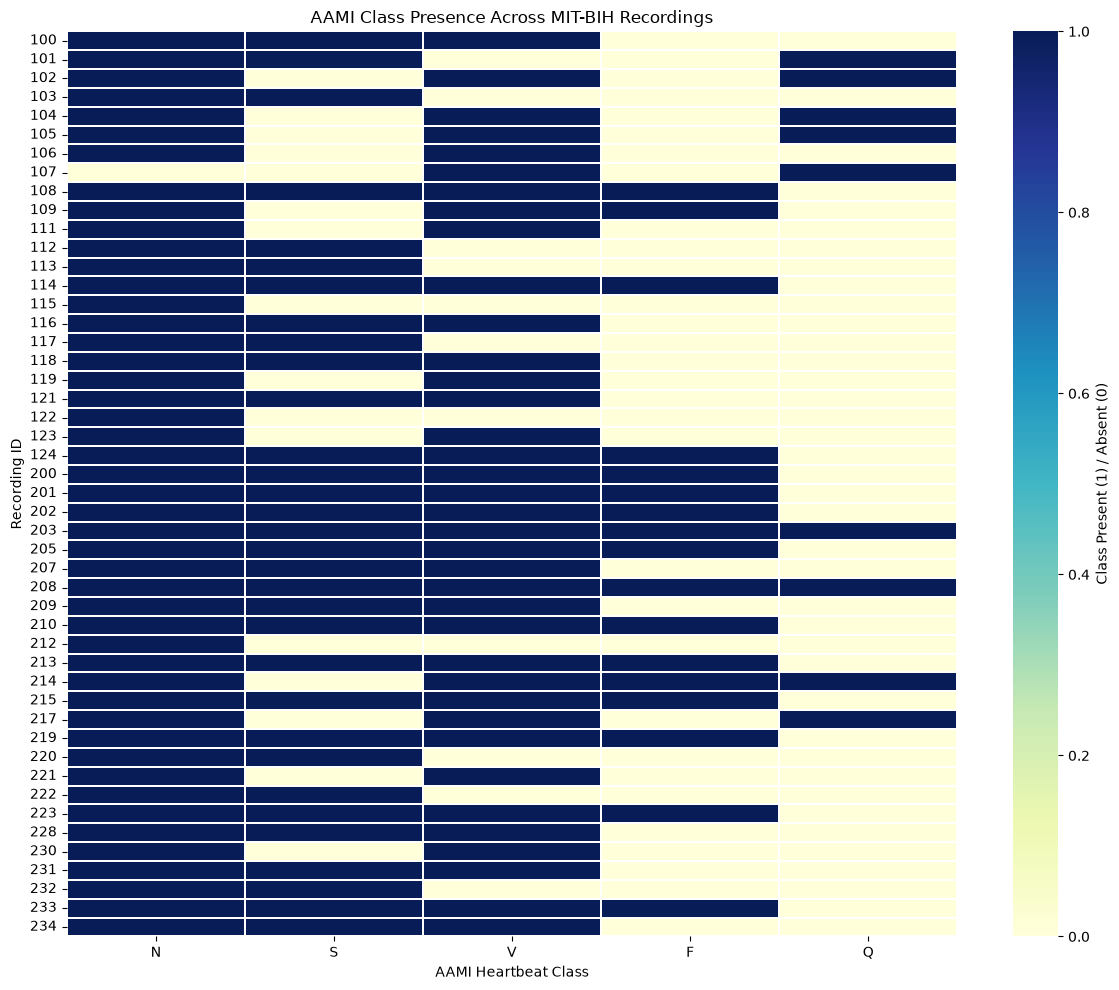

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare recording-level class presence
class_presence = recording_class_counts.set_index("record_id")[
    ["N", "S", "V", "F", "Q"]
]

# Convert counts into presence/absence
class_presence = (class_presence > 0).astype(int)

plt.figure(figsize=(12, 10))

sns.heatmap(
    class_presence,
    cmap="YlGnBu",
    linewidths=0.3,
    cbar_kws={"label": "Class Present (1) / Absent (0)"}
)

plt.title("AAMI Class Presence Across MIT-BIH Recordings")
plt.xlabel("AAMI Heartbeat Class")
plt.ylabel("Recording ID")

plt.tight_layout()
plt.show()

### 6.14 Visualization of Recording-Level Class Distribution

A binary heatmap was generated to visualize the presence or absence of the five AAMI heartbeat categories across the 48 MIT-BIH recordings.

Dark cells indicate that a heartbeat category is present in a recording, whereas light cells indicate its absence.

The visualization reveals differences in class coverage across recordings.

The N category is widely distributed, while F and Q are present in substantially fewer recordings.

These findings suggest that the dataset exhibits both class imbalance and recording-level heterogeneity in class representation.

This distinction is important for the subsequent experimental design because a model must be evaluated on recordings that were not used during training.

The heatmap represents class presence or absence rather than the frequency of individual heartbeat categories.

## 7. ECG Signal Diagnostics

### 7.1 Objective

This stage investigates the statistical characteristics of ECG signals using time-series diagnostic methods.

The objective is to identify signal properties that may influence preprocessing and machine learning strategy selection.

The initial analysis will use the MLII channel from MIT-BIH recording 100.

### 7.2 Diagnostic Methods

The following methods will be investigated:

1. **Augmented Dickey-Fuller (ADF) Test:** Examines the null hypothesis that the signal contains a unit root.
2. **KPSS Test:** Examines the null hypothesis that the signal is stationary around a constant level or deterministic trend, depending on the selected specification.
3. **Rolling Variance:** Examines how signal variability changes over time.

Both ADF and KPSS will be used because they have different null hypotheses and provide complementary evidence about stationarity.

### 7.3 Signal Representation

The original ECG signal is a continuous physiological time series containing repeated cardiac waveforms.

Stationarity tests will initially be applied to the raw MLII signal as an exploratory analysis. Their results will be interpreted carefully because periodic cardiac activity, baseline variation, and recording characteristics may affect the tests.

Further analysis may investigate derived representations, such as RR intervals and signal features.

### 7.4 Expected Outcome

This analysis will provide preliminary evidence about the stationarity and variance characteristics of the ECG signal.

The findings will later be considered alongside signal quality and class distribution when selecting suitable preprocessing and machine learning strategies.

In [56]:
# Extract the original MLII ECG signal

ecg_signal = record.p_signal[:, 0]

print("Signal channel:", record.sig_name[0])
print("Number of samples:", len(ecg_signal))
print("Sampling frequency:", record.fs)
print("Duration (seconds):", len(ecg_signal) / record.fs)
print("Mean amplitude:", np.mean(ecg_signal))
print("Standard deviation:", np.std(ecg_signal))
print("Minimum amplitude:", np.min(ecg_signal))
print("Maximum amplitude:", np.max(ecg_signal))

Signal channel: MLII
Number of samples: 650000
Sampling frequency: 360
Duration (seconds): 1805.5555555555557
Mean amplitude: -0.3062989769230769
Standard deviation: 0.19319954213721688
Minimum amplitude: -2.715
Maximum amplitude: 1.435


### 7.3 Stationarity Analysis Using ADF and KPSS

The Augmented Dickey-Fuller (ADF) and Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests will be applied to the original MLII ECG signal.

The ADF test uses the null hypothesis of a unit root, whereas the KPSS test uses the null hypothesis of stationarity.

Using both tests allows the stationarity characteristics to be examined from complementary statistical perspectives.

The significance level will be set to 0.05.

The test statistics, p-values, and corresponding interpretations will be recorded for further analysis.

In [59]:
from statsmodels.tsa.stattools import adfuller, kpss

# ADF test
adf_result = adfuller(ecg_signal)

# KPSS test
kpss_result = kpss(
    ecg_signal,
    regression="c",
    nlags="auto"
)

print("ADF TEST")
print("-------------------------")
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

print("\nKPSS TEST")
print("-------------------------")
print("KPSS Statistic:", kpss_result[0])
print("p-value:", kpss_result[1])

print("\nInterpretation at 0.05 significance level:")

if adf_result[1] < 0.05:
    print("ADF: Reject the unit-root null hypothesis.")
else:
    print("ADF: Fail to reject the unit-root null hypothesis.")

if kpss_result[1] < 0.05:
    print("KPSS: Reject the stationarity null hypothesis.")
else:
    print("KPSS: Fail to reject the stationarity null hypothesis.")

ADF TEST
-------------------------
ADF Statistic: -61.579436188234766
p-value: 0.0

KPSS TEST
-------------------------
KPSS Statistic: 3.845423543577324
p-value: 0.01

Interpretation at 0.05 significance level:
ADF: Reject the unit-root null hypothesis.
KPSS: Reject the stationarity null hypothesis.


/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/3518141412.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(ecg_signal)
/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/3518141412.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/3518141412.py:7: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 

### 7.4 ADF and KPSS Test Results

The ADF and KPSS tests were applied to the original MLII ECG signal from MIT-BIH recording 100.

The significance level was set to 0.05.

| Test | Test Statistic | p-value | Decision |
|---|---:|---:|---|
| ADF | -61.5794 | 0.0000 | Reject unit-root null hypothesis |
| KPSS | 3.8454 | 0.01 | Reject stationarity null hypothesis |

The ADF test rejects the unit-root null hypothesis, while the KPSS test rejects the null hypothesis of stationarity around a constant level.

The combination of these results does not support a straightforward stationary or conventional unit-root classification.

This finding indicates that additional investigation of the signal's statistical properties is necessary.

Potential factors include periodic cardiac activity, baseline variation, and time-varying signal characteristics.

The results are preliminary and are based on the original MLII recording. Further analysis using signal segments and derived features will be conducted before assigning a final stationarity condition.

### 7.6 Rolling Variance Analysis

Rolling variance is used to investigate changes in ECG signal variability over time.

For this experiment, the complete MLII signal from recording 100 will be analysed using a 10-second rolling window.

The analysis aims to:

- Examine temporal changes in signal variability.
- Identify periods of relatively high or low variance.
- Investigate whether signal variability remains consistent throughout the recording.

The rolling variance results will provide additional information about the statistical characteristics of the ECG signal and support subsequent diagnostic interpretation.

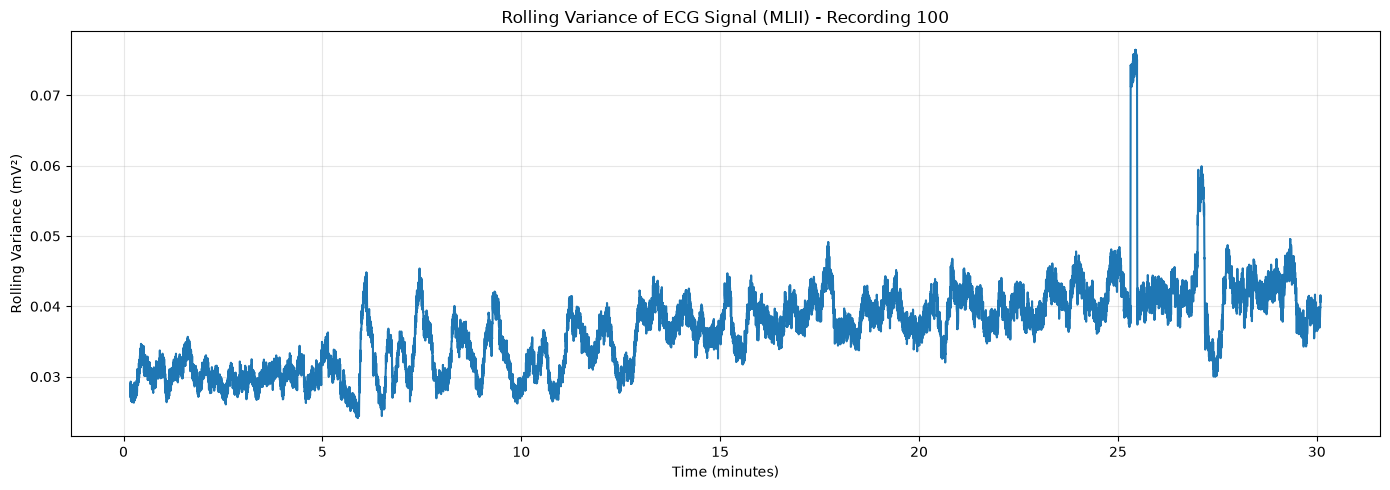

In [63]:
# Rolling variance analysis of the complete recording

window_size = 10 * record.fs  # 10-second window (3600 samples)

ecg_series = pd.Series(ecg_signal)

rolling_variance = ecg_series.rolling(
    window=window_size,
    min_periods=window_size
).var()

# Time axis in minutes
time_axis = np.arange(len(ecg_signal)) / record.fs / 60

# Plot rolling variance
plt.figure(figsize=(14, 5))

plt.plot(time_axis, rolling_variance)

plt.title("Rolling Variance of ECG Signal (MLII) - Recording 100")
plt.xlabel("Time (minutes)")
plt.ylabel("Rolling Variance (mV²)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [65]:
print("Rolling Variance Summary")
print("------------------------")
print("Mean:", rolling_variance.mean())
print("Median:", rolling_variance.median())
print("Standard deviation:", rolling_variance.std())
print("Minimum:", rolling_variance.min())
print("Maximum:", rolling_variance.max())

Rolling Variance Summary
------------------------
Mean: 0.036555582594188764
Median: 0.0368836618948911
Standard deviation: 0.005985080624568448
Minimum: 0.024117163700950787
Maximum: 0.07647175511522777


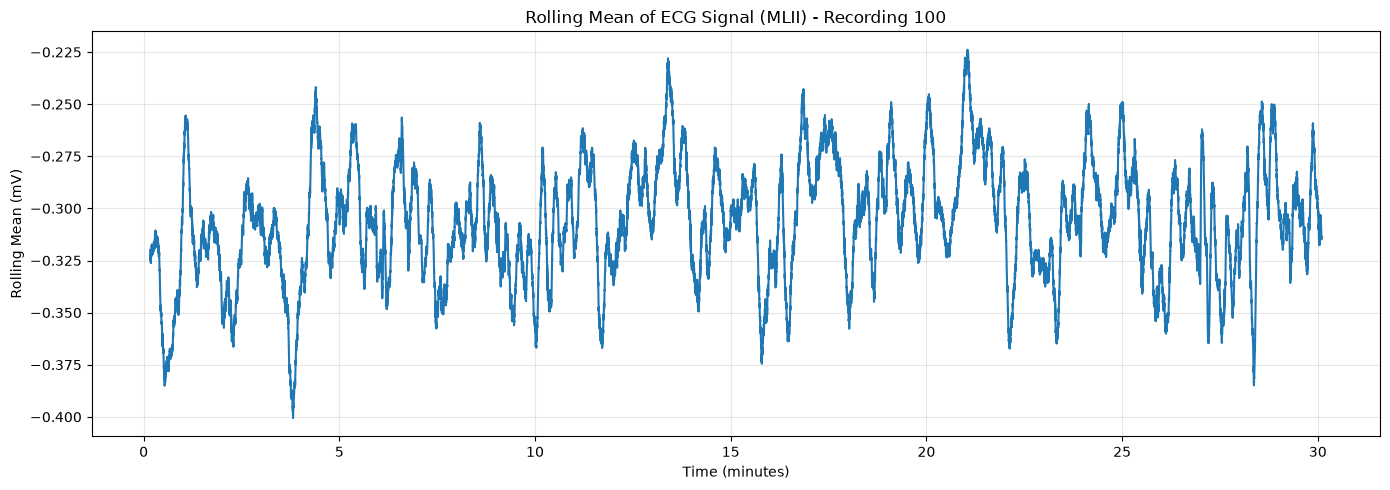

In [67]:
# Rolling mean analysis

rolling_mean = ecg_series.rolling(
    window=window_size,
    min_periods=window_size
).mean()

plt.figure(figsize=(14, 5))

plt.plot(time_axis, rolling_mean)

plt.title("Rolling Mean of ECG Signal (MLII) - Recording 100")
plt.xlabel("Time (minutes)")
plt.ylabel("Rolling Mean (mV)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 7.6.2 Numerical Summary of Rolling Variance

The numerical summary provides further evidence of temporal variation in the ECG signal.

The mean rolling variance was 0.03656 mV², while the median was 0.03688 mV². The standard deviation was 0.00599 mV². The minimum and maximum values were 0.02412 mV² and 0.07647 mV², respectively.

The maximum rolling variance was approximately 3.17 times the minimum. This indicates that some periods of the recording exhibit considerably greater signal variability than others.

Together with the rolling variance plot, these results suggest that signal variability changes over time. This finding will be considered alongside the ADF and KPSS tests in the overall diagnostic analysis.

### 7.7 Rolling Mean Analysis

Rolling mean analysis is used to examine changes in the average amplitude of the ECG signal over time.

The complete MLII signal from recording 100 will be analysed using a 10-second rolling window, consistent with the rolling variance analysis.

The objectives are to:
- Examine changes in the local average signal amplitude.
- Identify possible baseline shifts over time.
- Compare rolling mean patterns with the rolling variance results.

This analysis provides additional information about the temporal characteristics of the ECG signal.

### 7.7.1 Rolling Mean: Preliminary Observations

The rolling mean plot shows noticeable fluctuations in the local average amplitude of the ECG signal throughout recording 100.

The rolling mean does not remain at a constant level. Several upward and downward movements are visible across the recording, including a decrease to approximately −0.40 mV near 4 minutes and an increase to approximately −0.225 mV near 21 minutes.

No clear long-term upward or downward trend is observed. Instead, the plot indicates repeated local changes in the average signal level.

These observations suggest that the local mean of the ECG signal varies over time. The findings will be considered together with rolling variance and the ADF and KPSS test results.

In [72]:
print("Rolling Mean Summary")
print("--------------------")
print("Mean:", rolling_mean.mean())
print("Median:", rolling_mean.median())
print("Standard deviation:", rolling_mean.std())
print("Minimum:", rolling_mean.min())
print("Maximum:", rolling_mean.max())

Rolling Mean Summary
--------------------
Mean: -0.30623288230181844
Median: -0.30593472222222223
Standard deviation: 0.028119674595523326
Minimum: -0.4005902777777778
Maximum: -0.2238986111111111


### 7.7.2 Numerical Summary of Rolling Mean

The numerical summary shows that the mean of the rolling mean values is −0.30623 mV, while the median is −0.30593 mV. The standard deviation is 0.02812 mV.

The minimum and maximum rolling mean values are −0.40059 mV and −0.22390 mV, respectively. This range indicates that the local average amplitude changes across different sections of the recording.

The results support the visual observation that the ECG signal does not maintain a constant local mean throughout the recording. However, these findings should be interpreted alongside the stationarity tests and other signal diagnostics rather than used as independent evidence of nonstationarity.

In [75]:
diagnostic_summary = pd.DataFrame({
    "Diagnostic": [
        "ADF statistic",
        "ADF p-value",
        "KPSS statistic",
        "KPSS p-value",
        "Mean rolling variance",
        "Median rolling variance",
        "Std rolling variance",
        "Mean rolling mean",
        "Median rolling mean",
        "Std rolling mean"
    ],
    "Value": [
        adf_result[0],
        adf_result[1],
        kpss_result[0],
        kpss_result[1],
        rolling_variance.mean(),
        rolling_variance.median(),
        rolling_variance.std(),
        rolling_mean.mean(),
        rolling_mean.median(),
        rolling_mean.std()
    ]
})

diagnostic_summary

,Diagnostic,Value
0,ADF statistic,-61.579436
1,ADF p-value,0.000000
2,KPSS statistic,3.845424
3,KPSS p-value,0.010000
4,Mean rolling variance,0.036556
5,Median rolling variance,0.036884
6,Std rolling variance,0.005985
7,Mean rolling mean,-0.306233
8,Median rolling mean,-0.305935
9,Std rolling mean,0.028120


### 7.8 Consolidated Diagnostic Findings: Recording 100

The diagnostic analysis of MIT-BIH recording 100 combined the ADF test, KPSS test, rolling variance, and rolling mean.

The ADF test produced a statistic of −61.5794 with a p-value of approximately 0.0000, leading to rejection of the unit-root null hypothesis. In contrast, the KPSS test produced a statistic of 3.8454 with a reported p-value of 0.0100, leading to rejection of the null hypothesis of stationarity around a constant.

The rolling variance analysis showed temporal variation, with a mean of 0.03656 and a standard deviation of 0.00599. The rolling mean also fluctuated, with a mean of −0.30623 mV and a standard deviation of 0.02812 mV.

Overall, the two stationarity tests provide conflicting evidence, while the rolling statistics indicate changes in local signal characteristics over time. These findings suggest that a more detailed investigation across multiple ECG recordings is necessary before drawing conclusions about the stationarity properties of the MIT-BIH database.

At this stage, the results are preliminary and are limited to recording 100.

### 7.9 Stationarity Analysis Across All 48 Recordings

The previous analysis examined the complete ECG signal from recording 100. However, a single recording may not represent the statistical characteristics of the entire MIT-BIH Arrhythmia Database.

Therefore, this section extends the ADF and KPSS tests to all 48 recordings.

For each recording, the MLII channel will be extracted and analysed separately using the same test configurations:

- ADF test with its default settings.
- KPSS test with `regression="c"` and `nlags="auto"`.

The results will be collected in a single dataframe to examine the consistency of stationarity characteristics across recordings.

This analysis will help identify whether the statistical properties observed in recording 100 are common across the dataset or vary between recordings.

In [79]:
from statsmodels.tsa.stattools import adfuller, kpss
from tqdm.notebook import tqdm

record_ids = wfdb.get_record_list("mitdb")

stationarity_results = []

for record_id in tqdm(record_ids, desc="Analysing ECG recordings"):

    record_data = wfdb.rdrecord(
        record_id,
        pn_dir="mitdb",
        physical=True
    )

    # Extract MLII channel
    signal = record_data.p_signal[:, 0]

    # ADF test
    adf_result = adfuller(signal)

    # KPSS test
    kpss_result = kpss(
        signal,
        regression="c",
        nlags="auto"
    )

    stationarity_results.append({
        "record": record_id,
        "ADF_statistic": adf_result[0],
        "ADF_p_value": adf_result[1],
        "KPSS_statistic": kpss_result[0],
        "KPSS_p_value": kpss_result[1]
    })

stationarity_df = pd.DataFrame(stationarity_results)

stationarity_df

Analysing ECG recordings:   0%|          | 0/48 [00:00<?, ?it/s]

/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/1727356610.py:20: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(signal)
/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/1727356610.py:23: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/1727356610.py:23: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 o

,record,ADF_statistic,ADF_p_value,KPSS_statistic,KPSS_p_value
0,100,-61.579436,0.0,3.845424,0.010000
1,101,-36.275160,0.0,0.223014,0.100000
2,102,-72.365267,0.0,2.700239,0.010000
3,103,-37.036648,0.0,0.077364,0.100000
4,104,-68.667543,0.0,0.252366,0.100000
5,105,-57.732336,0.0,0.045563,0.100000
6,106,-64.253657,0.0,0.600652,0.022577
7,107,-71.213612,0.0,0.016352,0.100000
8,108,-25.711500,0.0,0.008662,0.100000
9,109,-82.555508,0.0,0.123771,0.100000


### 7.9 Stationarity Analysis Across All 48 MIT-BIH Recordings

The ADF and KPSS tests were applied to the complete MLII signal from all 48 recordings in the MIT-BIH Arrhythmia Database.

At a 5% significance level, the ADF test rejected the unit-root null hypothesis for all 48 recordings. The reported ADF p-values were 0.000000, indicating strong evidence against the presence of a unit root.

The KPSS test produced different results. For 19 recordings, the reported p-value was below 0.05, leading to rejection of the null hypothesis of stationarity around a constant. For the remaining 29 recordings, the null hypothesis was not rejected.

The results therefore indicate two patterns:

- In 29 recordings, both tests are consistent with stationarity.
- In 19 recordings, the tests provide conflicting evidence.

These findings suggest that the statistical characteristics of the raw ECG signals vary across recordings. Therefore, a single stationarity classification may not adequately describe the entire dataset.

The results should be interpreted cautiously because the KPSS test generated interpolation warnings for some recordings, and its reported p-values may be limited by the available lookup-table range. Furthermore, failure to reject the KPSS null hypothesis does not prove stationarity.

These findings are preliminary and will be considered alongside additional signal diagnostics before selecting appropriate modelling strategies.

In [82]:
alpha = 0.05

adf_rejections = (stationarity_df["ADF_p_value"] < alpha).sum()
kpss_rejections = (stationarity_df["KPSS_p_value"] < alpha).sum()

kpss_non_rejections = (
    stationarity_df["KPSS_p_value"] >= alpha
).sum()

print("STATIONARITY TEST SUMMARY")
print("-------------------------")
print("Total recordings:", len(stationarity_df))
print("ADF rejections:", adf_rejections)
print("KPSS rejections:", kpss_rejections)
print("KPSS non-rejections:", kpss_non_rejections)

STATIONARITY TEST SUMMARY
-------------------------
Total recordings: 48
ADF rejections: 48
KPSS rejections: 19
KPSS non-rejections: 29


In [84]:
# Identify recordings where KPSS rejects stationarity

kpss_rejected_records = stationarity_df[
    stationarity_df["KPSS_p_value"] < 0.05
]["record"].tolist()

print("Recordings with KPSS rejection:")
print(kpss_rejected_records)

print("\nNumber of recordings:", len(kpss_rejected_records))

Recordings with KPSS rejection:
['100', '102', '106', '112', '115', '117', '119', '122', '123', '200', '201', '205', '213', '215', '220', '221', '223', '231', '232']

Number of recordings: 19


In [86]:
# Identify recordings in each KPSS group

kpss_rejected = set(kpss_rejected_records)

rolling_variance_results = []

for record_id in tqdm(record_ids, desc="Calculating rolling variance"):

    record_data = wfdb.rdrecord(
        record_id,
        pn_dir="mitdb",
        physical=True
    )

    signal = record_data.p_signal[:, 0]

    # 10-second rolling window
    window_size = int(record_data.fs * 10)

    rolling_var = (
        pd.Series(signal)
        .rolling(window=window_size)
        .var()
        .dropna()
    )

    rolling_variance_results.append({
        "record": record_id,
        "KPSS_group": (
            "KPSS_rejected"
            if record_id in kpss_rejected
            else "KPSS_not_rejected"
        ),
        "mean_rolling_variance": rolling_var.mean(),
        "median_rolling_variance": rolling_var.median(),
        "std_rolling_variance": rolling_var.std(),
        "max_rolling_variance": rolling_var.max()
    })

rolling_variance_df = pd.DataFrame(rolling_variance_results)

rolling_variance_df.head()

Calculating rolling variance:   0%|          | 0/48 [00:00<?, ?it/s]

,record,KPSS_group,mean_rolling_variance,median_rolling_variance,std_rolling_variance,max_rolling_variance
0,100,KPSS_rejected,0.036556,0.036884,0.005985,0.076472
1,101,KPSS_not_rejected,0.066098,0.055639,0.062732,0.788614
2,102,KPSS_rejected,0.035371,0.035170,0.003238,0.052062
3,103,KPSS_not_rejected,0.099052,0.095531,0.043714,0.783677
4,104,KPSS_not_rejected,0.060853,0.054074,0.019598,0.219877


In [88]:
from pathlib import Path

project_path = Path.cwd()

notebook_path = project_path / "1st experiment.ipynb"

print("Project directory:", project_path)
print("Notebook exists:", notebook_path.exists())
print("Notebook path:", notebook_path)

Project directory: /Users/hmdsahed/ECG Prof. Ozaydin
Notebook exists: True
Notebook path: /Users/hmdsahed/ECG Prof. Ozaydin/1st experiment.ipynb
